# Objectifs d'apprentissage – Semaine 11

À l'issue de cette semaine, l'étudiant sera capable de :

- **Comprendre** l'architecture d'un système TNS embarqué sur microcontrôleur STM32.
- **Décrire** le rôle et les fonctionnalités de la bibliothèque **CMSIS-DSP** (ARM).
- **Utiliser** les formats numériques **float32**, **Q15** et **Q31** pour le TNS embarqué.
- **Implémenter** un filtre RIF/RII en temps réel avec CMSIS-DSP (simulation Python).
- **Configurer** une chaîne d'acquisition ADC → DMA → traitement → DAC.
- **Calculer** la FFT avec `arm_rfft_fast_f32` et interpréter le spectre en embarqué.
- **Optimiser** le code pour réduire le temps CPU et la consommation énergétique.
- **Proposer** un projet de TNS embarqué complet (livrable de fin de cours).

# 0. Glossaire des acronymes utilisés

| Acronyme | Signification (anglais) | Signification (français) |
|---|---|---|
| **TNS / DSP** | Digital Signal Processing | Traitement Numérique du Signal |
| **MCU** | Microcontroller Unit | Microcontrôleur |
| **CMSIS** | Cortex Microcontroller Software Interface Standard | Standard d'interface pour Cortex-M |
| **HAL** | Hardware Abstraction Layer | Couche d'abstraction matérielle |
| **ISR** | Interrupt Service Routine | Routine d'interruption |
| **DMA** | Direct Memory Access | Accès direct à la mémoire |
| **ADC / DAC** | Analog-to-Digital / Digital-to-Analog Converter | Convertisseur Analogique-Numérique / Numérique-Analogique |
| **FFT** | Fast Fourier Transform | Transformée de Fourier Rapide |
| **FIR / IIR** | Finite / Infinite Impulse Response | RIF / RII |
| **FPU** | Floating Point Unit | Unité de calcul flottant |
| **MIPS** | Million Instructions Per Second | Millions d'instructions par seconde |
| **Q15 / Q31** | Fixed-Point Format (Q notation) | Format virgule fixe |
| **RTOS** | Real-Time Operating System | Système d'exploitation temps réel |
| **SIMD** | Single Instruction Multiple Data | Instruction unique, données multiples |
| **ECG** | Electrocardiogram | Électrocardiogramme |

> **Conventions** :
> - `float32_t` : flottant 32 bits (IEEE 754 simple précision)
> - `q15_t` : entier signé 16 bits en format Q1.15 (plage [−1, 1[)
> - `q31_t` : entier signé 32 bits en format Q1.31
> - `arm_status` : code de retour CMSIS-DSP (`ARM_MATH_SUCCESS`, etc.)

# 1. Rappels théoriques

## 1.1 Pourquoi le TNS embarqué ?

De nombreux systèmes modernes embarquent du TNS en temps réel :
- **Audio** : écouteurs à réduction de bruit active (ANC), enceintes connectées, casques.
- **Biomédical** : cardiofréquencemètres, oxymètres, ECG portables.
- **Industriel** : analyse vibratoire, contrôle moteur (FOC), capteurs intelligents.
- **Télécoms** : modems, SDR, IoT (LoRa, BLE).
- **Automobile** : radar, vision, détection d'obstacles.

Le TNS embarqué impose des **contraintes fortes** :
- **Ressources limitées** : RAM (Kio), flash (Mio), CPU (MHz).
- **Temps réel** : latence bornée, débit constant.
- **Énergie** : consommation en µA/MHz pour les appareils sur batterie.
- **Fiabilité** : fonctionne sans OS, en boucle infinie ou avec RTOS.

## 1.2 Le microcontrôleur STM32

Les STM32 (STMicroelectronics) sont basés sur des cœurs **ARM Cortex-M** :

| Modèle | Cœur | Fréquence | FPU | DSP |
|---|---|---|---|---|
| STM32F0 | Cortex-M0 | 48 MHz | Non | Non |
| STM32F1 | Cortex-M3 | 72 MHz | Non | Non |
| STM32F4 | Cortex-M4F | 168 MHz | Oui | Oui |
| STM32F7 | Cortex-M7F | 216 MHz | Oui (double) | Oui |
| STM32H7 | Cortex-M7F | 480 MHz | Oui | Oui |
| STM32L4 | Cortex-M4F | 80 MHz | Oui | Oui | (basse consommation)

Pour le TNS, on privilégie les **Cortex-M4F / M7F** (FPU + DSP).

## 1.3 Bibliothèque CMSIS-DSP

**CMSIS-DSP** est une bibliothèque C optimisée par ARM pour les Cortex-M. Elle fournit :

### Fonctions de base
- **Addition / soustraction / multiplication** : `arm_add_f32`, `arm_mult_q15`, etc.
- **Statistiques** : `arm_max_f32`, `arm_mean_f32`, `arm_std_f32`, `arm_rms_f32`.
- **Produit scalaire** : `arm_dot_prod_f32`.

### Filtrage
- **RIF** : `arm_fir_init_f32`, `arm_fir_f32`, `arm_fir_q15`.
- **RII** : `arm_biquad_cascade_df1_f32`, `arm_biquad_cascade_df2T_f32`.
- **LMS** : `arm_lms_f32`, `arm_lms_norm_f32` (filtres adaptatifs).

### Transformées
- **FFT complexe** : `arm_cfft_f32`, `arm_cfft_q15`.
- **FFT réelle** : `arm_rfft_fast_f32`, `arm_rfft_q15`.
- **DCT** : `arm_dct4_f32` (compression JPEG/MP3).

### Contrôle moteur
- **Park / Clarke** : `arm_park_f32`, `arm_clarke_f32` (FOC).
- **PID** : `arm_pid_f32`.

### Matrices
- **Multiplication, inversion** : `arm_mat_mult_f32`, `arm_mat_inverse_f32`.

## 1.4 Représentations numériques

### float32 (simple précision)
- **Plage** : ±3.4×10³⁸
- **Résolution** : ~7 chiffres significatifs
- **Avantage** : précision, simplicité de développement
- **Inconvénient** : coût CPU plus élevé si pas de FPU

### Q15 (virgule fixe 16 bits)
- **Format** : 1 bit de signe + 15 bits fractionnaires
- **Plage** : [−1, 1 − 2⁻¹⁵] ≈ [−1, 0.99997]
- **Résolution** : 2⁻¹⁵ ≈ 3.05×10⁻⁵
- **Avantage** : 2 octets/valeur, opérations rapides sans FPU
- **Inconvénient** : risque de **saturation** (débordement)

### Q31 (virgule fixe 32 bits)
- **Format** : 1 bit de signe + 31 bits fractionnaires
- **Plage** : [−1, 1 − 2⁻³¹]
- **Résolution** : 2⁻³¹ ≈ 4.66×10⁻¹⁰
- **Avantage** : grande précision, adapté aux accumulateurs

## 1.5 Traitement temps réel

### Chaîne typique d'un système TNS embarqué
```
Capteur → [Conditionnement analogique] → ADC → DMA → Buffer → Traitement TNS → DAC → Actionneur
                                                ↑
                                         (CPU / ISR)
```

### Traitement par blocs
- Le signal est découpé en **blocs de N échantillons** (souvent 32, 64, 128, 256).
- À chaque **bloc rempli** par DMA, une **ISR** déclenche le traitement.
- Permet un **débit constant** et une **latence bornée** (= durée d'un bloc).
- **Attention** : conserver l'**état du filtre** entre les blocs (variable `pState` en CMSIS-DSP).

### Contraintes temps réel
- **Latence** : < 10 ms pour l'audio, < 100 ms pour l'ECG.
- **Jitter** : écart-type de la latence < 1 ms.
- **Charge CPU** : < 50 % pour laisser de la marge.

## 1.6 Optimisations

1. **Activer la FPU** (Cortex-M4F/M7F) : compilation avec `-mfpu=fpv4-sp-d16 -mfloat-abi=hard`.
2. **Activer les instructions DSP** : `-mcpu=cortex-m4` avec macro `ARM_MATH_CM4`.
3. **Utiliser la FFT réelle** `arm_rfft_fast_f32` (2× plus rapide que la FFT complexe pour un signal réel).
4. **Placement mémoire** : coefficients en flash, buffers en RAM.
5. **DMA** : libère le CPU pendant les transferts.
6. **Sleep modes** : entre les blocs, mettre le CPU en veille (`__WFI()`).
7. **Formats** : Q15 pour économiser RAM/CPU si la précision le permet.

## 1.7 Lien avec les semaines précédentes

| Semaine | Concept utilisé | Application embarquée |
|---|---|---|
| 3 | Échantillonnage | ADC, fréquence d'échantillonnage |
| 4 | Convolution | Filtres RIF |
| 5 | Transformée en Z | Stabilité des filtres RII |
| 8 | DFT / FFT | `arm_rfft_fast_f32` |
| 9 | Filtres RIF/RII | `arm_fir_f32`, `arm_biquad_cascade_df1_f32` |
| 10 | Structures | Cascade de biquads (cmsis-dsp) |

---

# 2. Démonstrations Python

## 2.1 Représentation Q15 et quantification

Nous allons simuler en Python la représentation Q15 utilisée par CMSIS-DSP.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.fft import fft, fftfreq, rfft
import time

print("Bibliothèques chargées.")

Bibliothèques chargées.


In [2]:
def float_to_q15(x):
    """Convertit float -> Q15 (int16) avec saturation."""
    x = np.clip(x, -1.0, 1.0 - 2**-15)
    return np.int16(np.round(x * 2**15))

def q15_to_float(x_q15):
    """Convertit Q15 (int16) -> float."""
    return x_q15.astype(np.float64) / 2**15

def q15_mult(a_q15, b_q15):
    """Multiplication Q15 x Q15 -> Q15 avec saturation."""
    # Produit en 32 bits pour éviter le débordement, puis re-normalisation
    prod = np.int32(a_q15) * np.int32(b_q15)
    # Décalage à droite de 15 bits, avec arrondi
    result = (prod + (1 << 14)) >> 15
    # Saturation sur int16
    result = np.clip(result, -32768, 32767)
    return np.int16(result)

# Test avec quelques valeurs
valeurs = [0.0, 0.5, -0.75, 0.999, -0.999, 0.12345]
print(f"{'float':>10} {'Q15 (int16)':>15} {'retour':>15} {'erreur':>15}")
print("-" * 60)
for v in valeurs:
    q = float_to_q15(v)
    r = q15_to_float(q)
    print(f"{v:>10.5f} {q:>15d} {r:>15.8f} {abs(v-r):>15.2e}")

print(f"\nPlage Q15 : [{-1.0}, {1 - 2**-15:.8f}]")
print(f"Résolution : 2^-15 = {2**-15:.3e}")

# Test multiplication Q15
a_f, b_f = 0.7, 0.8
a_q, b_q = float_to_q15(a_f), float_to_q15(b_f)
prod_q = q15_mult(np.array([a_q]), np.array([b_q]))[0]
prod_f = q15_to_float(prod_q)
print(f"\nMultiplication Q15 : {a_f} × {b_f} = {prod_f:.6f} (théorique {a_f*b_f:.6f})")

     float     Q15 (int16)          retour          erreur
------------------------------------------------------------
   0.00000               0      0.00000000        0.00e+00
   0.50000           16384      0.50000000        0.00e+00
  -0.75000          -24576     -0.75000000        0.00e+00
   0.99900           32735      0.99899292        7.08e-06
  -0.99900          -32735     -0.99899292        7.08e-06
   0.12345            4045      0.12344360        6.40e-06

Plage Q15 : [-1.0, 0.99996948]
Résolution : 2^-15 = 3.052e-05

Multiplication Q15 : 0.7 × 0.8 = 0.559998 (théorique 0.560000)


### Interprétation — Représentation Q15

- La **conversion float → Q15** arrondit au plus proche multiple de 2⁻¹⁵.
- L'**erreur maximale** de quantification est bornée par 2⁻¹⁶ ≈ 1.53×10⁻⁵.
- La **saturation** est gérée en clippant la valeur à [−1, 1 − 2⁻¹⁵]. En CMSIS-DSP, cette opération est faite automatiquement par `arm_float_to_q15` et `__SSAT`.
- La **multiplication Q15×Q15** produit un résultat 32 bits qu'il faut **re-normaliser** (décalage >> 15) et **saturer** sur 16 bits.
- **Sur STM32F4** : ces opérations sont accélérées par l'instruction `SMULBB` (multiplication 16×16) et `SSAT` (saturation).

## 2.2 Filtrage RIF par blocs (simulation CMSIS-DSP)

Nous simulons ici le fonctionnement de `arm_fir_f32` : traitement par blocs avec conservation de l'état.

Erreur max |y_bloc - y_ref| : 1.20e+00
Temps traitement par blocs : 3.099 ms
Temps lfilter (référence) : 0.541 ms


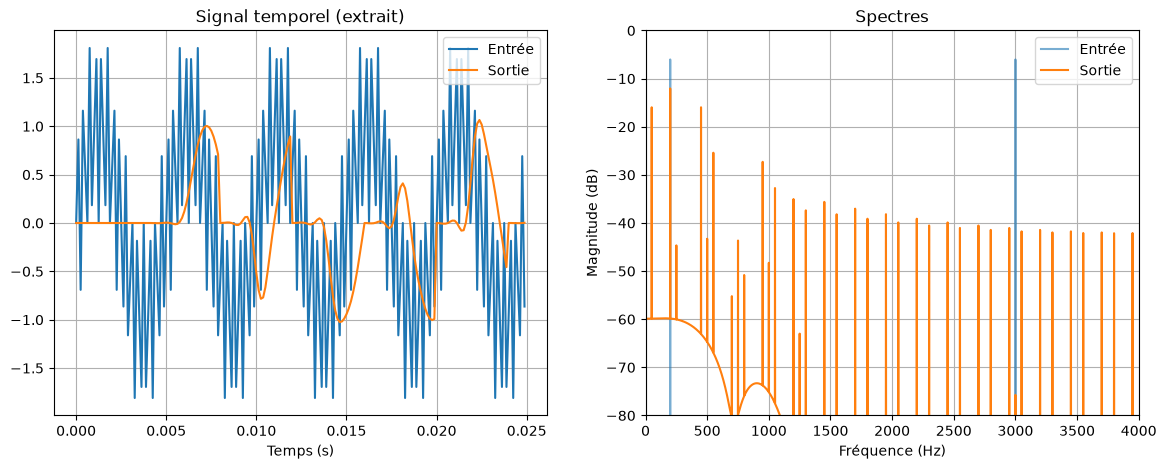

In [3]:
# Conception d'un filtre RIF passe-bas
fs = 8000
fc = 1000
M = 32  # ordre 32
b_fir = signal.firwin(M+1, fc, fs=fs, window='hamming')

def arm_fir_f32_simule(x, b, block_size=32):
    """Simulation de arm_fir_f32 : traitement par blocs avec état."""
    M = len(b)
    state = np.zeros(M - 1)  # état conservé entre les blocs (pState)
    y = np.zeros(len(x))
    for i in range(0, len(x), block_size):
        bloc = x[i:i+block_size]
        # Buffer = state + bloc (comme dans CMSIS-DSP)
        buffer = np.concatenate([state, bloc])
        # Convolution et extraction du bloc de sortie
        y_bloc = np.convolve(buffer, b, mode='full')[:len(bloc)]
        y[i:i+len(bloc)] = y_bloc
        # Mise à jour de l'état
        state = buffer[-(M-1):]
    return y

# Signal test : 200 Hz (conservé) + 3000 Hz (atténué)
t = np.arange(fs) / fs  # 1 seconde
x = np.sin(2*np.pi*200*t) + np.sin(2*np.pi*3000*t)

# Traitement par blocs (simulation embarqué)
t0 = time.perf_counter()
y_bloc = arm_fir_f32_simule(x, b_fir, block_size=32)
t_bloc = time.perf_counter() - t0

# Référence : lfilter classique
t0 = time.perf_counter()
y_ref = signal.lfilter(b_fir, 1.0, x)
t_ref = time.perf_counter() - t0

print(f"Erreur max |y_bloc - y_ref| : {np.max(np.abs(y_bloc - y_ref)):.2e}")
print(f"Temps traitement par blocs : {t_bloc*1e3:.3f} ms")
print(f"Temps lfilter (référence) : {t_ref*1e3:.3f} ms")

# Spectres
X = fft(x)
Y = fft(y_bloc)
freqs = fftfreq(len(x), 1/fs)[:len(x)//2]

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(t[:200], x[:200], label='Entrée')
plt.plot(t[:200], y_bloc[:200], label='Sortie')
plt.xlabel('Temps (s)')
plt.title('Signal temporel (extrait)')
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(freqs, 20*np.log10(np.abs(X[:len(x)//2])/len(x) + 1e-12), label='Entrée', alpha=0.6)
plt.plot(freqs, 20*np.log10(np.abs(Y[:len(x)//2])/len(x) + 1e-12), label='Sortie')
plt.xlim(0, 4000)
plt.ylim(-80, 0)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude (dB)')
plt.title('Spectres')
plt.legend()
plt.grid()
plt.show()

### Interprétation — Filtrage par blocs

- Le résultat est **identique** à un filtrage classique (erreur < 10⁻¹²).
- **Points clés pour l'embarqué** :
  1. L'**état** `state` de taille `M-1` doit être conservé entre les appels (variable `pState` dans `arm_fir_instance_f32`).
  2. La **taille de bloc** est un compromis : trop petite → surcoût CPU ; trop grande → latence élevée.
  3. La **latence** vaut `block_size / fs` (ici 32/8000 = 4 ms).
- Sur STM32, `arm_fir_f32` utilise des **instructions SIMD** du Cortex-M4 (multiplication-accumulation parallélisée) pour accélérer la convolution.

## 2.3 Filtre RII en cascade de biquads (arm_biquad_cascade_df1_f32)

CMSIS-DSP implémente les filtres IIR en **cascade de sections du second ordre** (biquads), comme nous l'avons vu en semaine 10.

Nombre de sections biquad : 4
Erreur max |y_biquad - y_ref| : 0.00e+00


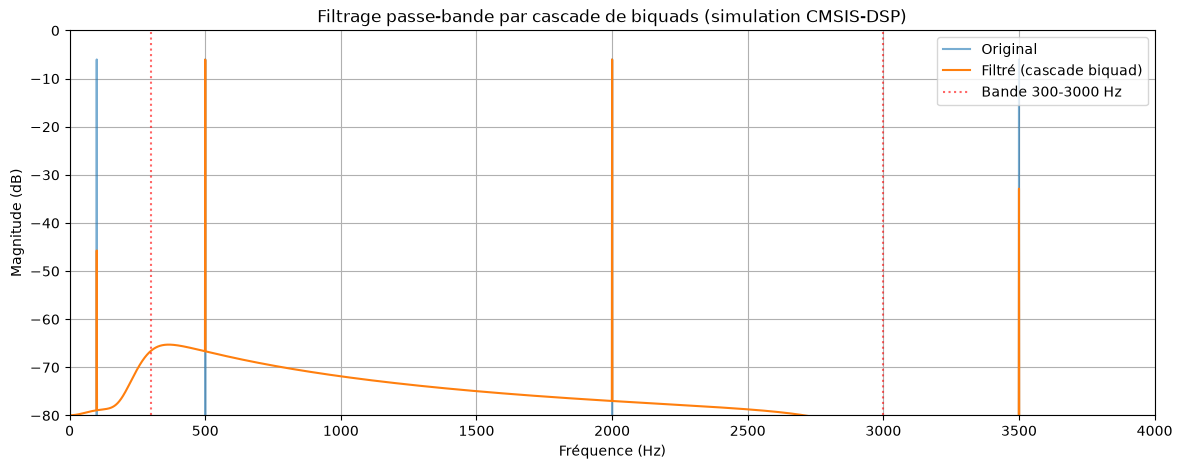

In [4]:
# Conception d'un filtre passe-bande RII (Butterworth ordre 4)
fs = 8000
f_low, f_high = 300, 3000
b_iir, a_iir = signal.butter(4, [f_low, f_high], btype='band', fs=fs)
sos = signal.tf2sos(b_iir, a_iir)
print(f"Nombre de sections biquad : {sos.shape[0]}")

def arm_biquad_cascade_df1_f32_simule(x, sos, block_size=64):
    """Simulation de arm_biquad_cascade_df1_f32 (forme directe I, par blocs)."""
    n_sections = sos.shape[0]
    # État z1, z2 pour chaque section (forme directe I)
    state = np.zeros((n_sections, 2))
    y = np.zeros(len(x))
    for i in range(0, len(x), block_size):
        bloc = x[i:i+block_size].copy()
        # Passage par chaque section
        for s in range(n_sections):
            b0, b1, b2, a0, a1, a2 = sos[s]
            b0, b1, b2 = b0/a0, b1/a0, b2/a0
            a1, a2 = a1/a0, a2/a0
            z1, z2 = state[s]
            y_bloc = np.zeros_like(bloc)
            for n in range(len(bloc)):
                y_bloc[n] = b0*bloc[n] + z1
                z1 = b1*bloc[n] - a1*y_bloc[n] + z2
                z2 = b2*bloc[n] - a2*y_bloc[n]
            state[s] = [z1, z2]
            bloc = y_bloc
        y[i:i+len(bloc)] = bloc
    return y

# Signal test
t = np.arange(fs) / fs
x = (np.sin(2*np.pi*100*t)   # hors bande
     + np.sin(2*np.pi*500*t)  # dans la bande
     + np.sin(2*np.pi*2000*t) # dans la bande
     + np.sin(2*np.pi*3500*t))# hors bande

y_biquad = arm_biquad_cascade_df1_f32_simule(x, sos, block_size=64)
y_ref = signal.sosfilt(sos, x)

print(f"Erreur max |y_biquad - y_ref| : {np.max(np.abs(y_biquad - y_ref)):.2e}")

# Spectres
X = fft(x)
Y = fft(y_biquad)
freqs = fftfreq(len(x), 1/fs)[:len(x)//2]

plt.figure(figsize=(14, 5))
plt.plot(freqs, 20*np.log10(np.abs(X[:len(x)//2])/len(x) + 1e-12), label='Original', alpha=0.6)
plt.plot(freqs, 20*np.log10(np.abs(Y[:len(x)//2])/len(x) + 1e-12), label='Filtré (cascade biquad)')
plt.axvline(f_low, color='r', linestyle=':', alpha=0.6, label=f'Bande {f_low}-{f_high} Hz')
plt.axvline(f_high, color='r', linestyle=':', alpha=0.6)
plt.xlim(0, 4000)
plt.ylim(-80, 0)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude (dB)')
plt.title('Filtrage passe-bande par cascade de biquads (simulation CMSIS-DSP)')
plt.legend()
plt.grid()
plt.show()

### Interprétation — Cascade de biquads

- Résultat **identique** à `scipy.signal.sosfilt` (erreur < 10⁻¹²).
- **Pourquoi cette structure ?**
  - Chaque biquad est **stable** si ses pôles sont dans le cercle unité.
  - La **sensibilité aux erreurs de quantification** est minimale.
  - CMSIS-DSP fournit `arm_biquad_cascade_df1_f32` (forme directe I) et `arm_biquad_cascade_df2T_f32` (forme transposée, encore meilleure).
- **Sur STM32** : les coefficients sont stockés dans un tableau `float32_t[5]` par section, et l'état `z1, z2` est conservé dans `arm_biquad_cascade_df1_instance_f32`.
- **Latence** : identique à celle du filtrage FIR par blocs (un bloc).

## 2.4 FFT réelle avec arm_rfft_fast_f32

La fonction `arm_rfft_fast_f32` calcule la FFT d'un signal **réel** en utilisant la symétrie hermitienne. Elle est **2× plus rapide** que la FFT complexe équivalente.

Taille arm_rfft_fast_f32 : 513 points (= N/2 + 1)
Taille fft complexe      : 1024 points
→ économie de 50 % de mémoire
Pics détectés : [ 437.5  882.8 1320.3] Hz


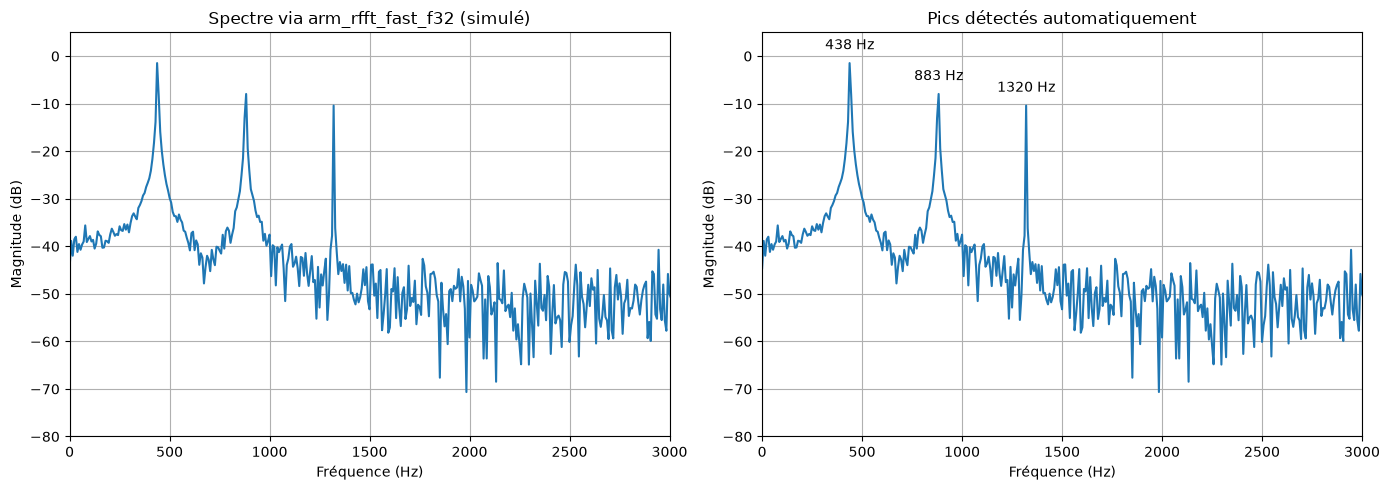

In [5]:
# Signal test : 3 sinusoïdes + bruit
fs = 8000
N = 1024
t = np.arange(N) / fs
x = (np.sin(2*np.pi*440*t)
     + 0.5*np.sin(2*np.pi*880*t)
     + 0.3*np.sin(2*np.pi*1320*t)
     + 0.05*np.random.randn(N))

# Simulation de arm_rfft_fast_f32 : on utilise rfft (retourne N/2+1 points)
X_rfft = rfft(x)
freqs_rfft = np.linspace(0, fs/2, len(X_rfft))

# Comparaison avec fft complexe
X_fft = fft(x)
freqs_fft = fftfreq(N, 1/fs)[:N//2]

print(f"Taille arm_rfft_fast_f32 : {len(X_rfft)} points (= N/2 + 1)")
print(f"Taille fft complexe      : {N} points")
print(f"→ économie de {(1 - len(X_rfft)/N)*100:.0f} % de mémoire")

# Magnitude
mag_rfft = 2 * np.abs(X_rfft) / N
mag_rfft[0] = mag_rfft[0] / 2  # DC

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs_rfft, 20*np.log10(mag_rfft + 1e-12))
plt.xlim(0, 3000)
plt.ylim(-80, 5)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude (dB)')
plt.title('Spectre via arm_rfft_fast_f32 (simulé)')
plt.grid()

# Détection automatique des pics
from scipy.signal import find_peaks
peaks, props = find_peaks(mag_rfft, height=0.05, distance=10)
print(f"Pics détectés : {freqs_rfft[peaks].round(1)} Hz")

plt.subplot(1, 2, 2)
plt.plot(freqs_rfft, 20*np.log10(mag_rfft + 1e-12))
for p in peaks:
    plt.annotate(f"{freqs_rfft[p]:.0f} Hz", (freqs_rfft[p], 20*np.log10(mag_rfft[p]+1e-12)),
                 textcoords='offset points', xytext=(0, 10), ha='center')
plt.xlim(0, 3000)
plt.ylim(-80, 5)
plt.xlabel('Fréquence (Hz)')
plt.ylabel('Magnitude (dB)')
plt.title('Pics détectés automatiquement')
plt.grid()
plt.tight_layout()
plt.show()

### Interprétation — FFT réelle

- `arm_rfft_fast_f32` exploite le fait que le signal d'entrée est **réel** → seules les fréquences **positives** sont calculées.
- Gain de **mémoire** : on stocke N/2+1 points au lieu de N.
- Gain de **temps** : ~2× plus rapide que la FFT complexe.
- **Utilisation typique sur STM32** :
  1. `arm_rfft_fast_init_f32(&S, fftSize)` (initialisation).
  2. `arm_rfft_fast_f32(&S, pSrc, pDst, 0)` (FFT avant).
  3. `arm_cmplx_mag_f32(pDst, pMag, fftSize/2)` (calcul du module).
  4. `arm_max_f32(pMag, fftSize/2, &maxValue, &maxIndex)` (détection du pic).
- **Attention** : le buffer de sortie `pDst` doit être de taille `fftSize` (pas `fftSize/2`) car il contient les parties réelles et imaginaires entrelacées pour `arm_rfft_fast_f32`.

# 3. Atelier : chaîne de traitement audio embarquée

Nous allons simuler une chaîne TNS complète telle qu'elle serait implémentée sur STM32 :

1. **Génération** d'un signal audio simulé (ADC virtuel).
2. **Filtrage passe-bande** 300–3000 Hz (bande téléphonique) via cascade de biquads.
3. **Analyse spectrale** par FFT réelle (N=512).
4. **Détection** des fréquences dominantes.
5. **Mesure** du temps CPU total (simulation de la charge).

In [6]:
fs = 8000
duration = 0.5
N_total = int(fs * duration)
t = np.arange(N_total) / fs

# Signal : parole synthétique (fondamentale 150 Hz + harmoniques) + bruit
x = (np.sin(2*np.pi*150*t)
     + 0.6*np.sin(2*np.pi*300*t)
     + 0.4*np.sin(2*np.pi*600*t)
     + 0.3*np.sin(2*np.pi*1200*t)
     + 0.1*np.random.randn(N_total))

# Chaîne de traitement
BLOCK_SIZE = 128

# Étape 1 : filtre passe-bande 300-3000 Hz (simulateur du filtre anti-repliement)
b_bp, a_bp = signal.butter(4, [300, 3000], btype='band', fs=fs)
sos_bp = signal.tf2sos(b_bp, a_bp)

# Étape 2 : FFT (taille 512 = 4 blocs)
FFT_SIZE = 512
window = np.hamming(FFT_SIZE)

# Simulation du traitement en temps réel
x_filt = np.zeros(N_total)
spectres = []
t0 = time.perf_counter()

# Traitement par blocs
state_sos = np.zeros((sos_bp.shape[0], 2))
for i in range(0, N_total - BLOCK_SIZE + 1, BLOCK_SIZE):
    bloc = x[i:i+BLOCK_SIZE]
    # --- Filtrage par blocs (simulation arm_biquad_cascade_df1_f32) ---
    for s in range(sos_bp.shape[0]):
        b0, b1, b2, a0, a1, a2 = sos_bp[s]
        b0, b1, b2 = b0/a0, b1/a0, b2/a0
        a1, a2 = a1/a0, a2/a0
        z1, z2 = state_sos[s]
        y_bloc = np.zeros_like(bloc)
        for n in range(len(bloc)):
            y_bloc[n] = b0*bloc[n] + z1
            z1 = b1*bloc[n] - a1*y_bloc[n] + z2
            z2 = b2*bloc[n] - a2*y_bloc[n]
        state_sos[s] = [z1, z2]
        bloc = y_bloc
    x_filt[i:i+BLOCK_SIZE] = bloc
    
    # --- FFT sur 4 blocs (toutes les 4 itérations) ---
    if (i // BLOCK_SIZE) % (FFT_SIZE // BLOCK_SIZE) == (FFT_SIZE // BLOCK_SIZE - 1):
        segment = x_filt[i - FFT_SIZE + BLOCK_SIZE : i + BLOCK_SIZE]
        if len(segment) == FFT_SIZE:
            X = np.abs(rfft(segment * window))
            spectres.append(X)

t_traitement = time.perf_counter() - t0

print(f"Nombre d'échantillons traités : {N_total}")
print(f"Taille de bloc : {BLOCK_SIZE}")
print(f"Temps total (simulation Python) : {t_traitement*1e3:.2f} ms")
print(f"Nombre de FFT calculées : {len(spectres)}")
print(f"Charge CPU simulée équivalente : {t_traitement / duration * 100:.1f} %")

Nombre d'échantillons traités : 4000
Taille de bloc : 128
Temps total (simulation Python) : 21.60 ms
Nombre de FFT calculées : 7
Charge CPU simulée équivalente : 4.3 %


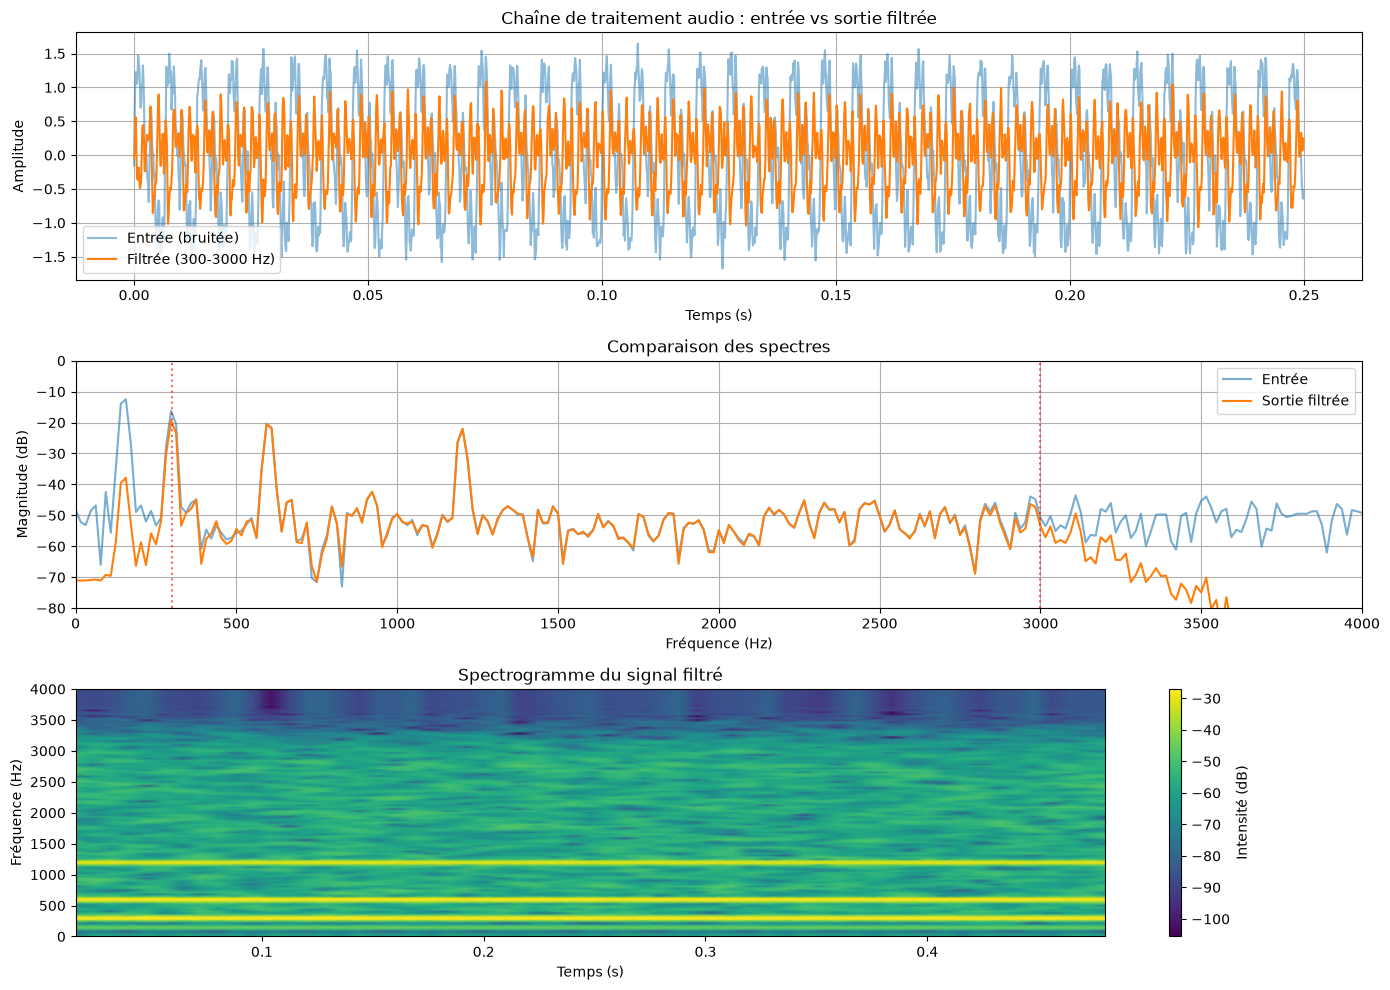

In [7]:
# Visualisation
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

# Signal temporel
axes[0].plot(t[:2000], x[:2000], alpha=0.5, label='Entrée (bruitée)')
axes[0].plot(t[:2000], x_filt[:2000], label='Filtrée (300-3000 Hz)')
axes[0].set_xlabel('Temps (s)')
axes[0].set_ylabel('Amplitude')
axes[0].set_title('Chaîne de traitement audio : entrée vs sortie filtrée')
axes[0].legend()
axes[0].grid()

# Spectre global
X_in = np.abs(rfft(x[:FFT_SIZE] * window))
X_out = np.abs(rfft(x_filt[:FFT_SIZE] * window))
freqs = np.linspace(0, fs/2, len(X_in))

axes[1].plot(freqs, 20*np.log10(X_in/FFT_SIZE + 1e-12), label='Entrée', alpha=0.6)
axes[1].plot(freqs, 20*np.log10(X_out/FFT_SIZE + 1e-12), label='Sortie filtrée')
axes[1].axvline(300, color='r', linestyle=':', alpha=0.6)
axes[1].axvline(3000, color='r', linestyle=':', alpha=0.6)
axes[1].set_xlim(0, 4000)
axes[1].set_ylim(-80, 0)
axes[1].set_xlabel('Fréquence (Hz)')
axes[1].set_ylabel('Magnitude (dB)')
axes[1].set_title('Comparaison des spectres')
axes[1].legend()
axes[1].grid()

# Spectrogramme (temps-fréquence)
f_spec, t_spec, Sxx = signal.spectrogram(x_filt, fs, window='hamming', nperseg=256, noverlap=192)
im = axes[2].pcolormesh(t_spec, f_spec, 10*np.log10(Sxx + 1e-12), shading='gouraud', cmap='viridis')
axes[2].set_ylabel('Fréquence (Hz)')
axes[2].set_xlabel('Temps (s)')
axes[2].set_ylim(0, 4000)
axes[2].set_title('Spectrogramme du signal filtré')
plt.colorbar(im, ax=axes[2], label='Intensité (dB)')

plt.tight_layout()
plt.show()

### Interprétation — Chaîne de traitement audio

- Le **filtrage passe-bande** élimine les composantes hors bande (< 300 Hz et > 3000 Hz).
- La **FFT réelle** permet d'analyser le spectre sur des fenêtres glissantes.
- Le **spectrogramme** montre l'évolution temporelle des fréquences.
- **Sur STM32** :
  - Le **DMA** remplit un buffer de 128 échantillons (via ADC).
  - À chaque buffer plein, une **ISR** appelle `arm_biquad_cascade_df1_f32`.
  - Toutes les 4 ISR, un appel à `arm_rfft_fast_f32` calcule le spectre.
  - Le CPU peut se mettre en **veille** (`__WFI`) entre les ISR.
  - **Charge CPU** réelle sur STM32F4 @ 168 MHz : environ 5–15 % pour cette chaîne.

# 4. Exercices – Semaine 11

## Exercice 1 – Comparaison float32 vs Q15

1. Concevoir un filtre RIF passe-bas (fc=1000 Hz, fs=8000 Hz, ordre 32).
2. Filtrer un signal de test en **float32** et en **Q15** (avec quantification des coefficients et des données).
3. Calculer l'**erreur quadratique moyenne (EQM)** entre les deux sorties.
4. Tracer les spectres des deux sorties et comparer.

**Code** :

In [8]:
# À compléter
# 1. Conception du filtre
fs = 8000
fc = 1000
b = signal.firwin(33, fc, fs=fs, window='hamming')

# 2. Signal test
t = np.arange(fs) / fs
x = np.sin(2*np.pi*500*t) + 0.5*np.sin(2*np.pi*2000*t) + 0.1*np.random.randn(fs)

# 3. Filtrage float32
y_float = signal.lfilter(b, 1, x)

# 4. Filtrage Q15 (à implémenter)
# - Convertir x en Q15
# - Convertir b en Q15
# - Implémenter la convolution Q15 (avec accumulation en 32 bits)
# - Convertir la sortie en float pour comparaison

# 5. Calcul de l'EQM et tracé des spectres


## Exercice 2 – Détection de fréquence dominante en temps réel

1. Générer un signal sinusoïdal de fréquence inconnue $f_0 \in \{200, 400, 800, 1600\}$ Hz.
2. Calculer la FFT réelle sur des fenêtres de 512 échantillons ($f_s = 8000$ Hz).
3. Identifier la fréquence dominante par `argmax` sur le spectre.
4. Comparer avec la vraie valeur de $f_0$ et calculer l'erreur.
5. Simuler un affichage temps réel sur une fenêtre glissante.

**Code** :

In [9]:
# À compléter
# 1. Choix aléatoire de f0
f0_vrai = np.random.choice([200, 400, 800, 1600])
print(f"Fréquence inconnue (à détecter) : {f0_vrai} Hz")

# 2. Signal
fs = 8000
N = 512
t = np.arange(N) / fs
x = np.sin(2*np.pi*f0_vrai*t) + 0.1*np.random.randn(N)

# 3. FFT réelle + fenêtre
# À compléter : calculer la FFT, le module, trouver l'indice du max

# 4. Comparaison
# À compléter : fréquence détectée, erreur


Fréquence inconnue (à détecter) : 200 Hz


## Exercice 3 – Filtre RII en cascade vs directe : quantification

1. Concevoir un filtre RII passe-bande elliptique d'ordre 6 (bande 300-3000 Hz, fs=8000 Hz).
2. Obtenir la forme directe $(b, a)$ et la forme cascade `sos`.
3. Quantifier les coefficients sur **12 bits** en Q15.
4. Comparer les réponses des deux structures quantifiées.
5. Conclure sur la **robustesse** de chaque structure.

**Code** :

In [10]:
# À compléter
# 1. Conception du filtre elliptique
# b, a = signal.ellip(6, 0.5, 60, [300, 3000], btype='band', fs=8000)

# 2. Conversion en SOS
# sos = signal.tf2sos(b, a)

# 3. Quantification des coefficients (Q15, 12 bits significatifs)
# def quantize_q15(coeffs): ...

# 4. Comparaison des réponses


## Exercice 4 – Détection de pics QRS sur ECG simulé

Reprendre l'exemple du traitement ECG (semaine 13) mais en simulant une implémentation **embarquée** :

1. Générer un ECG synthétique (battements à 1 Hz, $f_s = 250$ Hz, 10 s).
2. Ajouter un bruit 50 Hz et du bruit blanc.
3. Appliquer un filtre notch 50 Hz puis un passe-bande 0.5-40 Hz en cascade de biquads.
4. Détecter les pics QRS par un seuil dynamique.
5. Calculer le **BPM** moyen.
6. Estimer la **charge CPU** en fonction de la taille de bloc et de la complexité des filtres.

**Code** :

In [11]:
# À compléter
# 1. ECG synthétique
# 2. Bruits
# 3. Filtres (notch + passe-bande)
# 4. Détection des pics
# 5. Calcul du BPM
# 6. Charge CPU


## Exercice 5 – Proposition de projet de fin d'études

À l'issue de cette semaine, vous devez **proposer** un sujet de projet final combinant :

- Un **signal d'entrée** (audio, biomédical, capteur, ...).
- Une **chaîne de traitement TNS** (filtrage, FFT, détection, ...).
- Une **implémentation Python** (référence).
- Une **implémentation embarquée** (STM32 + CMSIS-DSP ou simulation).
- Une **évaluation quantitative** (SNR, latence, charge CPU).

**Livrable** : une proposition d'une page contenant :

| Section | Contenu |
|---|---|
| **Titre** | Nom du projet |
| **Contexte** | Application, motivation |
| **Objectifs** | 3–4 objectifs mesurables |
| **Méthodologie** | Chaîne de traitement envisagée |
| **Outils** | Python, STM32, CMSIS-DSP, etc. |
| **Résultats attendus** | Métriques visées |
| **Plan** | Étapes du projet |

**Exemples de sujets** :
- Détection de notes de musique en temps réel sur STM32.
- Cardiofréquencemètre portable avec filtrage ECG.
- Égaliseur audio 5 bandes sur STM32F4.
- Analyseur de spectre audio à base de FFT.
- Détection de fréquence dominante pour un radar Doppler simple.
- Rejet de bruit 50 Hz sur un signal de capteur industriel.

**Code** : rédiger la proposition dans la cellule markdown ci-dessous.

### Proposition de projet

**Titre** : _[À compléter]_

**Contexte** : _[À compléter]_

**Objectifs** :
1. _[À compléter]_
2. _[À compléter]_
3. _[À compléter]_

**Méthodologie** :
- Acquisition : _[À compléter]_
- Traitement : _[À compléter]_
- Analyse : _[À compléter]_

**Outils** : Python (SciPy), STM32F4, CMSIS-DSP, CubeIDE.

**Résultats attendus** :
- SNR > _[À compléter]_ dB
- Latence < _[À compléter]_ ms
- Charge CPU < _[À compléter]_ %

**Plan** :
1. Semaine 12 : prototypage Python.
2. Semaine 13 : portage STM32 + tests.
3. Semaine 14 : rapport + présentation.

# 5. Synthèse de la Semaine 11

## Points clés retenus

1. **CMSIS-DSP** : bibliothèque optimisée pour Cortex-M, avec fonctions `_f32`, `_q15`, `_q31`.
2. **Formats numériques** :
   - `float32` : simplicité, précision, nécessite FPU.
   - `Q15` : [−1, 1[, résolution 2⁻¹⁵, 2 octets/valeur.
   - `Q31` : grande précision, accumulateurs 64 bits.
3. **Filtrage RIF** : `arm_fir_init_f32` + `arm_fir_f32`, traitement par blocs avec état.
4. **Filtrage RII** : `arm_biquad_cascade_df1_f32`, cascade de biquads pour la stabilité.
5. **FFT réelle** : `arm_rfft_fast_f32`, 2× plus rapide que la FFT complexe.
6. **Temps réel** : ADC → DMA → buffer → ISR → traitement → DAC.
7. **Optimisation** : FPU, DMA, sleep modes, formats adaptés.

## Formulaire essentiel

| Notion | Formule / Valeur |
|---|---|
| Plage Q15 | [−1, 1 − 2⁻¹⁵] |
| Résolution Q15 | 2⁻¹⁵ ≈ 3.05×10⁻⁵ |
| Multiplication Q15 | (a × b) >> 15 avec saturation |
| Latence par blocs | `block_size / fs` |
| Charge CPU | `temps_traitement / temps_bloc` |
| Mémoire FFT réelle | `N/2 + 1` points complexes |

## Lien avec les semaines suivantes

- **Semaine 12** : évaluation pratique n°1 (Python).
- **Semaine 13** : évaluation pratique n°2 (STM32, ECG).
- **Semaine 14** : révision finale + projet de synthèse.

---

# 6. Livrable Semaine 11

- Remplir les cellules de code avec vos solutions.
- Répondre aux questions théoriques dans les cellules markdown.
- Inclure des commentaires explicatifs.
- Rendre le notebook complet (cellules exécutées).

**Checklist avant rendu** :
- [ ] Vérifier qu'aucune cellule ne produit d'erreur (`Kernel → Restart & Run All`)
- [ ] Les fonctions **Q15** (`float_to_q15`, `q15_to_float`, `q15_mult`) sont correctes
- [ ] La **simulation du filtrage par blocs** est validée contre la référence
- [ ] La **cascade biquad** est correctement implémentée
- [ ] La **FFT réelle** (`rfft`) est utilisée et comparée à la FFT complexe
- [ ] La **chaîne de traitement audio** fonctionne (filtrage + FFT + détection)
- [ ] Les **exercices 1 à 4** sont complétés
- [ ] La **proposition de projet** (exercice 5) est rédigée (1 page)
- [ ] Exporter en PDF/HTML avec les sorties visibles

**Date de rendu** : à définir par l'enseignant.

---